In [ ]:
%run ./CLN.ipynb

class CLN_Plane(CLN):
    def __init__(self, mode='E', a=0.01, sigma=1e6, mur=1):
        super().__init__(mode, a, sigma, mur)

        self.C = CoordSys3D('')
        self.x= sp.symbols('x', real=True)
        #self.y='y'

        self.namespace = {
                'cosh': np.cosh,
                'sinh': np.sinh,
                'sqrt': np.sqrt,
                'Pi': np.pi
        }

        if self.mode=='E': self.formulation=self.formulationE
        elif self.mode=='H': self.formulation=self.formulationH
        self.n_value=0
    
    def solveAmpere_by_integration(self, J, Hs=0):
        # アンペアの法則の z 成分 (d(Hy)/dx = Jz(x))
        x, a=self.x, self.a
        H=sp.integrate(J, x)
        if self.mode=='H': H=H-H.subs(x,a)+Hs
        return H
    
    def solveAmpere(self, J, Hs=0):
        if self.by_integ: return self.solveAmpere_by_integration(J, Hs)
        #  Jz=d/dx(Hy)  -Jy=d/dr(Hz)  
        # アンペアの法則の z 成分 (d(Hz)/dx = -Jy(x))
        x, a=self.x, self.a
        H = sp.Function('H')(x)
        eq=sp.Eq(sp.Derivative(H, x), J)
        if self.mode=='E':
            H=sp.dsolve(eq, H, ics={H.subs(x, 0): 0}).rhs
        elif self.mode=='H':
            H=sp.dsolve(eq, H, ics={H.subs(x, a): Hs}).rhs
        return H

    def solveFaraday_by_integration(self, B, Es=0):
        # ファラデーの法則の theta 成分 (-dEz / dx = -s * By)
        x, a=self.x, self.a
        E=sp.integrate(B, x)
        if self.mode=='E': E=E-E.subs(x,a)+E
        return E

    def solveFaraday(self, B, Es=0):
        if self.by_integ: return self.solveFaraday_by_integration(B, Es)
        # ファラデーの法則の teta 成分 (-dEy / dx = -s * Bz)
        x, a=self.x, self.a
        E = sp.Function('E')(x)
        eq=sp.Eq(sp.Derivative(E, x), B)
        if self.mode=='E': 
            E=sp.dsolve(eq, E, ics={E.subs(x, a): Es}).rhs   
        elif self.mode=='H': 
            E=sp.dsolve(eq, E, ics={E.subs(x, 0): 0}).rhs
        return E

    def solveFaraday_Neumann(self, By, Hs):
        #if self.by_integ: return self.solveFaraday_by_integration(By, Es)
        # ファラデーの法則の theta 成分 (-dEz / dx = -s * By)
        x, a=self.x, self.a
        Ez = sp.Function('Ez')(x)
        eq=sp.Eq(sp.Derivative(Ez, x), By)
        Ez=sp.dsolve(eq, Ez, ics={Ez.subs(x, a): Es}).rhs
        return Ez

    def Vintegrate(self, integrand):
        x=self.x
        a = self.a
        return sp.integrate(integrand, (x, 0, a))

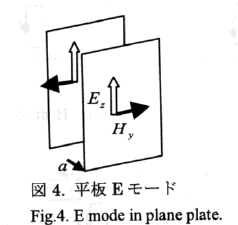

In [2]:
def formulationA(self, output=True):
    if output:
        display(Markdown("# ***** E mode in a plane *****"))
    """平板モデル：マクスウェル方程式からの自動導出と解析解・インピーダンスの算出（ステップごとのMarkdown表示付き）"""   
    x, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    Cart = self.C
    Cx = Cart.x  # 座標系の変数

    # ステップ1: ベクトルポテンシャル A と磁束密度 B, 磁界 H の定義
    Az_c = sp.Function('Az')(Cx)
    A = Az_c * Cart.k
    B = sp.vector.curl(A)
    H = B / mu

    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{A}} = {sp.latex(A)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\nabla \\times \\mathbf{{A}} = {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = \\frac{{\\mathbf{{B}}}}{{\\mu}} = {sp.latex(H)} \\end{{equation}}"))

    # ステップ2: 磁界の回転（curl H）の展開
    curl_H = sp.vector.curl(H).doit()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁界の回転 $\\nabla \\times \\mathbf{H}$ の展開**"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))

    # ステップ3: マクスウェル方程式（軸方向成分）の構築
    eq_maxwell_P = sp.Eq(curl_H.dot(Cart.k), (-sigma * s * A).dot(Cart.k))
    """
    if output:
        display(Markdown("---"))
        display(Markdown("### ** マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_maxwell_P)} \\end{{equation}}"))
    """
    # ステップ4: ヘルムホルツ型標準形への自動整理（Cylinder に倣った置換構造）
    Az_x = sp.Function('Az')(x)
    eq_z_standard = sp.Eq(
        sp.simplify(-eq_maxwell_P.lhs * mu).subs(Cx, x).subs(Az_c.subs(Cx, x), Az_x),
        sp.simplify(-eq_maxwell_P.rhs * mu).subs(Cx, x).subs(Az_c.subs(Cx, x), Az_x)
    )
    if output:
        display(Markdown("---"))
        display(Markdown("### ** マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_z_standard)} \\end{{equation}}"))

    # ステップ5: 境界条件を考慮した一般解の導出と電磁界・インピーダンスの算出
    C1, C2 = sp.symbols('C1 C2')
    As = -Es / s

    # dsolve を使用して境界条件（表面 x = a で Az = As）を直接指定して解く
    # ※中心対称性（x=0で微分が0）により、自動的に sinh の項（C2）が消える形になります
    sol = sp.dsolve(eq_z_standard, Az_x, ics={Az_x.subs(x, a): As, Az_x.subs(x, -a): As})
    sol=sol.simplify()
    numer, denom = sol.rhs.as_numer_denom()
    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)
    numer = numer.subs(alpha_val, k)/sp.exp(a*k)/sp.exp(k*x)/2
    denom = denom.subs(alpha_val, k)/sp.exp(a*k)/sp.exp(k*x)/2
    numer = numer.rewrite(sp.cosh).simplify()
    denom = denom.rewrite(sp.cosh).simplify()
    sol=numer/denom
    #display(sol)
    
    # 必要に応じて対称性から C2 係数を整理・抽出（C2=0 が自動適用、あるいは一般解の形を反映）
    #sol = general_sol.rhs.subs({C2: 0}) if C2 in general_sol.free_symbols else general_sol.rhs

    Ez = -s * sol
    Hy = -1 / mu * sp.Derivative(sol, x).doit()
    Z_expr = (Ez / Hy).subs({x: a}).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_z(x) = {sp.latex(Ez)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_y(x) = {sp.latex(Hy)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))

    Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    
    return Z_exact_sym

# 3. メソッドのバインドと実行
CLN_Plane.formulationE = formulationA


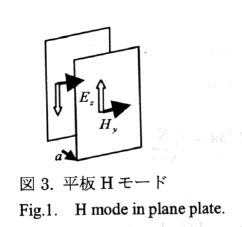

In [3]:
def formulationT(self, output=True):
    if output:
        display(Markdown("# ***** H mode in a plane *****"))
    """平板モデル：マクスウェル方程式からの自動導出と解析解・インピーダンスの算出（ステップごとのMarkdown表示付き）"""   
    x, a, s, sigma, mu= self.x, self.a, self.s, self.sigma, self.mu
    Hs=sp.Symbol('H_s', real=True)
    Cart = self.C
    Cx = Cart.x  # 座標系の変数

    # ステップ1: ベクトルポテンシャル A と磁束密度 B, 磁界 H の定義
    Tz_c = sp.Function('Tz')(Cx)
    T = Tz_c * Cart.k
    B=mu*T
    H = T

    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = {sp.latex(T)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\mu \\mathbf{{H}} = {sp.latex(B)} \\end{{equation}}"))

    # ステップ2: 磁界の回転（curl H）の展開
    J = sp.vector.curl(H).doit()
    E=J/sigma
    curl_E=sp.vector.curl(E)
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 電流密度 $\\mathbf{J}$ と電界 $\\mathbf{E}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{J}} = \\nabla \\times \\mathbf{{T}} = {sp.latex(J)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{E}} = \\frac{{\\mathbf{{J}}}}{{\\sigma}}  = {sp.latex(E)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{E}} = {sp.latex(curl_E)} \\end{{equation}}"))
    # ステップ3: マクスウェル方程式（軸方向成分）の構築

    eq_maxwell = sp.Eq(curl_E.dot(Cart.k), (-mu * s * H).dot(Cart.k))
    """
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 3】マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_maxwell)} \\end{{equation}}"))
    """
    # ステップ4: ヘルムホルツ型標準形への自動整理（Cylinder に倣った置換構造）
    Tz_x = sp.Function('Tz')(x)
    eq_z_standard = sp.Eq(
        sp.simplify(-eq_maxwell.lhs * sigma).subs(Cx, x).subs(Tz_c.subs(Cx, x), Tz_x),
        sp.simplify(-eq_maxwell.rhs * sigma).subs(Cx, x).subs(Tz_c.subs(Cx, x), Tz_x)
    )
    if output:
        display(Markdown("---"))
        display(Markdown("### **マクスウェル方程式（z方向成分）**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq_z_standard)} \\end{{equation}}"))

    # ステップ5: 境界条件を考慮した一般解の導出と電磁界・インピーダンスの算出
    C1, C2 = sp.symbols('C1 C2')
    Ts = Hs
    # dsolve を使用して境界条件（表面 x = a で Az = As）を直接指定して解く
    # ※中心対称性（x=0で微分が0）により、自動的に sinh の項（C2）が消える形になります
    sol = sp.dsolve(eq_z_standard, Tz_x, ics={Tz_x.subs(x, a): Hs, Tz_x.subs(x, -a): Hs})
    sol=sol.simplify()
    numer, denom = sol.rhs.as_numer_denom()
    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)
    numer = numer.subs(alpha_val, k)/sp.exp(a*k)/sp.exp(k*x)/2
    denom = denom.subs(alpha_val, k)/sp.exp(a*k)/sp.exp(k*x)/2
    numer = numer.rewrite(sp.cosh).simplify()
    denom = denom.rewrite(sp.cosh).simplify()
    sol=numer/denom
 
    # 必要に応じて対称性から C2 係数を整理・抽出（C2=0 が自動適用、あるいは一般解の形を反映）
    #sol = general_sol.rhs.subs({C2: 0}) if C2 in general_sol.free_symbols else general_sol.rhs

    Hz =sol
    Ey = -1 / sigma * sp.Derivative(sol, x).doit()
    Z_expr =-(Ey / Hz).subs({x: a}).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_z(x) = {sp.latex(Hz)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_y(x) = {sp.latex(Ey)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mu_r =Z/(sa\\mu_0)  \\end{{equation}}"))

    Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    
    return Z_exact_sym

# 3. メソッドのバインドと実行
CLN_Plane.formulationH = formulationT



# ***** E mode in a plane *****

---

### ** 磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{A} = \left(\operatorname{Az}{\left(\mathbf{{x}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

\begin{equation} \mathbf{B} = \nabla \times \mathbf{A} = \left(- \frac{d}{d \mathbf{{x}_{}}} \operatorname{Az}{\left(\mathbf{{x}_{}} \right)}\right)\mathbf{\hat{j}_{}} \end{equation}

\begin{equation} \mathbf{H} = \frac{\mathbf{B}}{\mu} = \left(- \frac{\frac{d}{d \mathbf{{x}_{}}} \operatorname{Az}{\left(\mathbf{{x}_{}} \right)}}{\mu}\right)\mathbf{\hat{j}_{}} \end{equation}

... (25 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), R_c + 1/(1/(5*R_c + 1/(1/(9*R_c + 1/(1/(13*R_c + 1/(1/(17*R_c) + 15/(L_c*s))) + 11/(L_c*s))) + 7/(L_c*s))) + 3/(L_c*s)))

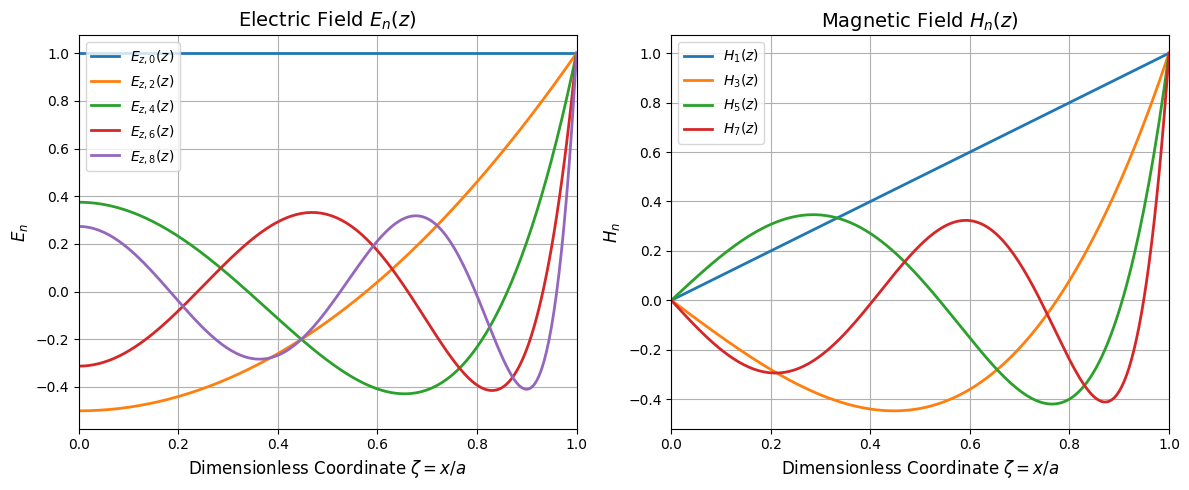

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi}


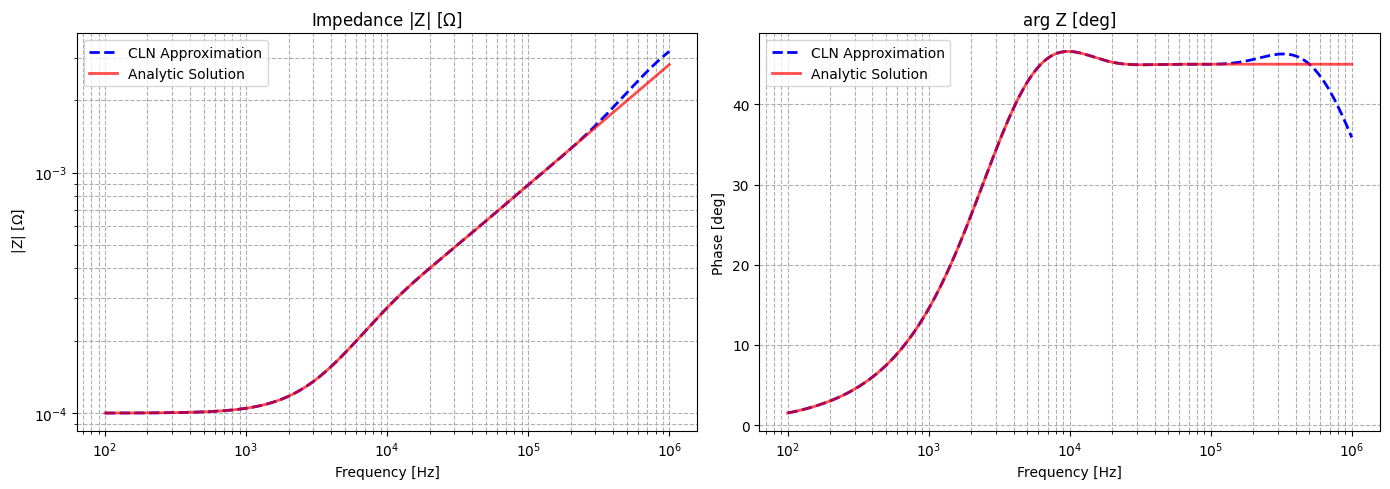

In [4]:
mode='E'
cln= CLN_Plane(mode)
if mode=='E': cln.formulationE()
else: cln.formulationH()
R, L, E, H, Z=cln.buildCLN('E_H', nmax=8)
cln.displayParameters()
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
cln.plot_Z(Z)

# ***** H mode in a plane *****

---

### ** 磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{H} = \left(\operatorname{Tz}{\left(\mathbf{{x}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

\begin{equation} \mathbf{B} = \mu \mathbf{H} = \left(\mu \operatorname{Tz}{\left(\mathbf{{x}_{}} \right)}\right)\mathbf{\hat{k}_{}} \end{equation}

---

... (26 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(3*R_c + 1/(1/(7*R_c + 1/(1/(11*R_c + 1/(1/(L_c*s/17 + 15*R_c) + 13/(L_c*s))) + 9/(L_c*s))) + 5/(L_c*s))) + 1/(L_c*s)))

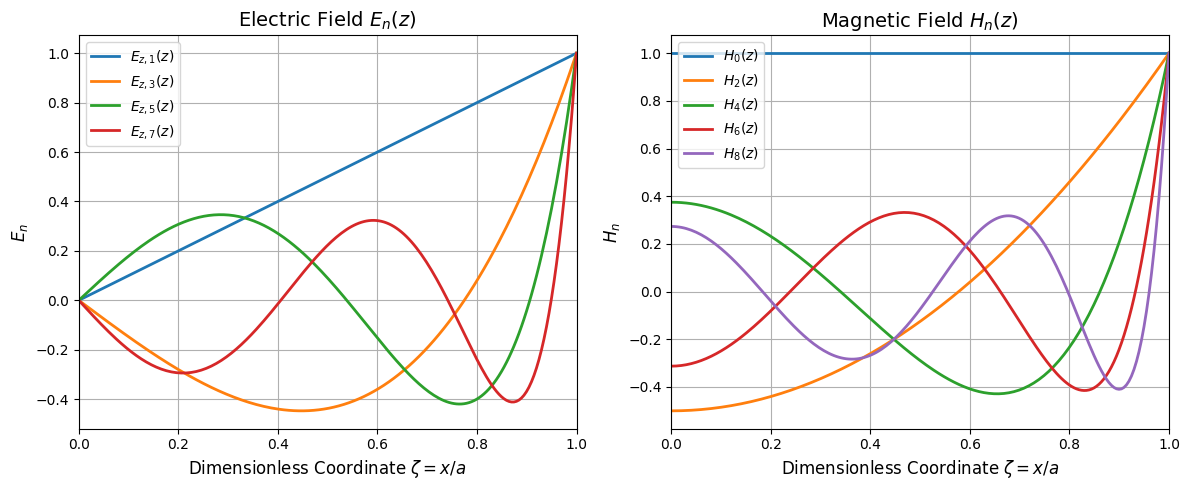

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi}


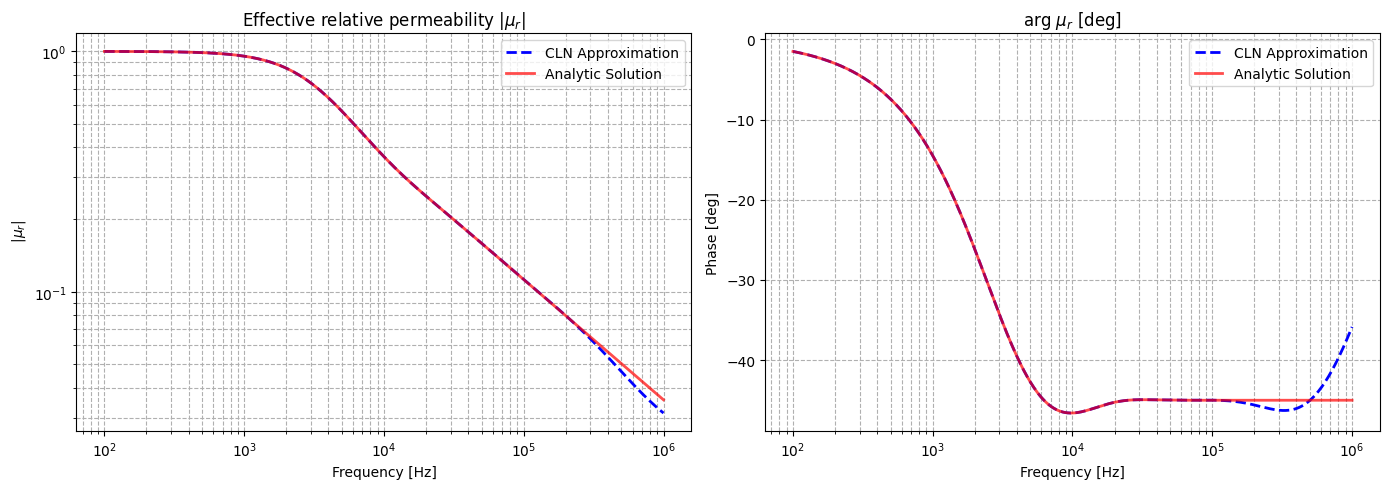

In [5]:
mode='H'
cln= CLN_Plane(mode)
if mode=='E': cln.formulationE()
else: cln.formulationH()
R, L, E, H, Z=cln.buildCLN('E_H', nmax=8)
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
cln.plot_Z(Z)

In [6]:
cln=CLN_Plane('E')
R, L, A, E, H, Z=cln.buildCLN('A', nmax=8)
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)


### **電界モード $E_{n}(z)$  ( $\zeta = r/a$)**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (6 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), R_c + 1/(1/(5*R_c + 1/(1/(9*R_c + 1/(1/(13*R_c + 1/(1/(17*R_c) + 15/(L_c*s))) + 11/(L_c*s))) + 7/(L_c*s))) + 3/(L_c*s)))

### **電界モード $E_{n}(z)$  ( $\zeta = r/a$)**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### **磁界モード $H_{n}(z)$   ( $\zeta = r/a$)**

... (7 outputs left out)

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(3*R_c + 1/(1/(7*R_c + 1/(1/(11*R_c + 1/(1/(L_c*s/17 + 15*R_c) + 13/(L_c*s))) + 9/(L_c*s))) + 5/(L_c*s))) + 1/(L_c*s)))

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi}


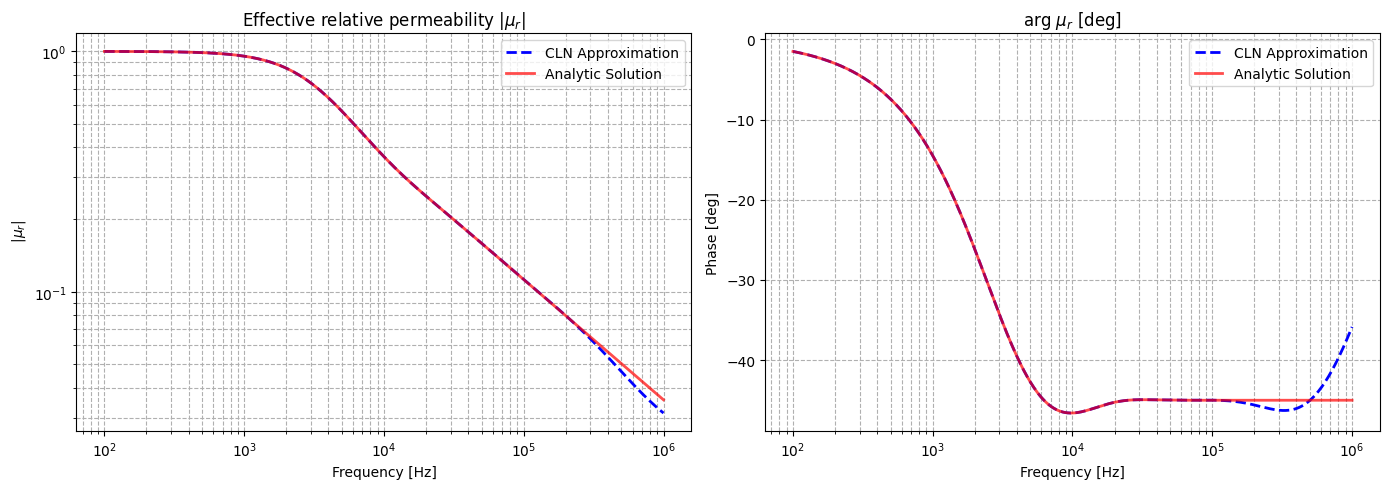

In [7]:
cln=CLN_Plane('H')
R, L, T, E, H, Z=cln.buildCLN('T', nmax=8)
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_Z(Z)